In [1]:
import sapien.physx as physx
physx.enable_gpu()
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"using {device}")

using cuda


In [2]:
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
policy = SmolVLAPolicy.from_pretrained("lerobot/smolvla_base")

/home/dl01e26/.conda/envs/vla/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`torch_dtype` is deprecated! Use `dtype` instead!


Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...
Reducing the number of VLM layers to 16 ...


In [3]:
for n, p in policy.named_parameters():   # inspecting the insane structure behind the model
    print(n, p.shape, p.requires_grad) 

model.vlm_with_expert.vlm.model.vision_model.embeddings.patch_embedding.weight torch.Size([768, 3, 16, 16]) False
model.vlm_with_expert.vlm.model.vision_model.embeddings.patch_embedding.bias torch.Size([768]) False
model.vlm_with_expert.vlm.model.vision_model.embeddings.position_embedding.weight torch.Size([1024, 768]) False
model.vlm_with_expert.vlm.model.vision_model.encoder.layers.0.self_attn.k_proj.weight torch.Size([768, 768]) False
model.vlm_with_expert.vlm.model.vision_model.encoder.layers.0.self_attn.k_proj.bias torch.Size([768]) False
model.vlm_with_expert.vlm.model.vision_model.encoder.layers.0.self_attn.v_proj.weight torch.Size([768, 768]) False
model.vlm_with_expert.vlm.model.vision_model.encoder.layers.0.self_attn.v_proj.bias torch.Size([768]) False
model.vlm_with_expert.vlm.model.vision_model.encoder.layers.0.self_attn.q_proj.weight torch.Size([768, 768]) False
model.vlm_with_expert.vlm.model.vision_model.encoder.layers.0.self_attn.q_proj.bias torch.Size([768]) False
mode

In [4]:
print("total params:", sum(p.numel() for p in policy.parameters()) / 1000000, "mil")
print("trainable params:", sum(p.numel() for p in policy.parameters() if p.requires_grad) / 1000000, "mil")

total params: 450.046176 mil
trainable params: 99.880992 mil


In [5]:
#setting up dataset and dataloader
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from torch.utils.data import DataLoader

dataset = LeRobotDataset(
    repo_id= "local/pickcube",
    root="/home/dl01e26/vla_pipeline/lerobot_demos"
)

sample = dataset[0]

print(sample["action"].shape) #random sample of the data that should give 8

print(dataset.meta.features.keys())   # or dataset.features
print(dataset.meta.camera_keys)
print(dataset.meta.stats.keys())


torch.Size([7])
dict_keys(['action', 'observation.state', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index', 'task', 'observation.images.base_camera'])
['observation.images.base_camera']
dict_keys(['action', 'observation.state', 'observation.images.base_camera', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index'])


In [ ]:
#The base dataset has a mismatch between the expected feature names the actual feature names
# so we tell the model what features to expect
from lerobot.configs.types import FeatureType
from lerobot.datasets.utils import dataset_to_policy_features
from lerobot.configs.policies import PreTrainedConfig
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.policies.factory import make_pre_post_processors

#Finding the features and the config for the model
features = dataset_to_policy_features(dataset.meta.features)
cfg = PreTrainedConfig.from_pretrained("lerobot/smolvla_base")
cfg.output_features = {k: f for k, f in features.items() if f.type is FeatureType.ACTION}
cfg.input_features = {k: f for k, f in features.items() if k not in cfg.output_features}

#initializing the model with the right config for the dataset
policy = SmolVLAPolicy.from_pretrained("lerobot/smolvla_base", config = cfg).to(device)
control_policy = SmolVLAPolicy.from_pretrained("lerobot/smolvla_base", config = cfg).to(device)

#we make our pre and post processor because we need tokens, not text as well as normalization.
preprocess, postprocess = make_pre_post_processors(
    policy.config, pretrained_path="lerobot/smolvla_base",
    dataset_stats=dataset.meta.stats,
) 

#we remake the dataset with delta_timestamps
from lerobot.datasets.factory import resolve_delta_timestamps

delta_timestamps = resolve_delta_timestamps(policy.config, dataset.meta)
dataset = LeRobotDataset(
    "local/pickcube",
    root = "/home/dl01e26/vla_pipeline/lerobot_demos",
    delta_timestamps = delta_timestamps,
)

data_loader = DataLoader(dataset, batch_size = 28, shuffle = True)

#to see if it works
batch = preprocess(next(iter(data_loader)))
with torch.no_grad():
    loss, info = policy.forward(batch)
    print(loss)
    print(info)

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...
Reducing the number of VLM layers to 16 ...
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...
Reducing the number of VLM layers to 16 ...
tensor(0.8079, device='cuda:0')
{'losses_after_forward': 0.8078808784484863, 'losses_after_rm_padding': 0.8078808784484863, 'loss': 0.8078808784484863}
Action mean/std: -0.059089820832014084 0.38119563460350037
State mean/std: 0.21028107404708862 1.1078624725341797


In [7]:
# LION optimiser as found via: https://github.com/google/automl/blob/master/lion/lion_pytorch.py
# Write up about it found here: https://aiwiki.ai/wiki/lion_optimizer perks is that it is a memory efficient optimiser that is perfect for smolVLA
import torch
from torch.optim import Optimizer as Optimiser

class LION(Optimiser):
    def __init__(self, params, lr=1e-4, betas=(0.9, 0.99), weight_decay=0):
        """Initialize the hyperparameters.

    Args:
      params (iterable): iterable of parameters to optimize or dicts defining
        parameter groups
      lr (float, optional): learning rate (default: 1e-4)
      betas (Tuple[float, float], optional): coefficients used for computing
        running averages of gradient and its square (default: (0.9, 0.99))
      weight_decay (float, optional): weight decay coefficient (default: 0)
    """
        defaults = dict(lr=lr, betas=betas, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                
                p.data.mul_(1 - group['lr'] * group['weight_decay'])
                
                grad = p.grad
                state = self.state[p]
                
                # State initialisation
                if len(state) == 0:
                # Exponential moving average of gradient values
                    state['exp_avg'] = torch.zeros_like(p)

                exp_avg = state['exp_avg']
                beta1, beta2 = group['betas']
                
                update = exp_avg * beta1 + grad * (1 - beta1)
                p.add_(update.sign(), alpha=-group['lr'])
                
                exp_avg.mul_(beta2).add_(grad, alpha=1 - beta2)
            
            return loss

In [ ]:
import time
from tqdm import tqdm
BATCH_COUNTER = 500
lr_aw = 5e-5
lr_lion = 2e-5 #documentation suggests that LION should be used with a lower learning rate than AdamW
weight_decay = 0.01
nEpoch = 2

params_to_update = []
for name, param in policy.named_parameters():
    if param.requires_grad:
        params_to_update.append(param)

opt = torch.optim.AdamW(params_to_update, lr = lr_aw, weight_decay = weight_decay)

#We need to check if the lion optimizer is actually faster in a more thorough test.
#opt = LION(params_to_update, lr = lr_lion) #IF this is how we get trainable parameters

# working on being able to change the loss function

#we need learning rate scheduler to avoid gradient explosion when training
# this scheduler starts low and linearly increases until it hits end_factor and then keeps the same learning rate. 
scheduler = torch.optim.lr_scheduler.LinearLR(
    opt, start_factor = 0.01, end_factor = 1.0, total_iters = 100
)

train_loss = []

policy.train()

print("BEGINNING TRAINING \n----------------------------------------------------------------------")
start_time = time.perf_counter()
for iEpoch in tqdm(range(nEpoch)):
    tot_loss = 0
    tot_part_batch = 0
    for ibatch, batch in tqdm(enumerate(data_loader)):

        opt.zero_grad()

        batch = preprocess(batch)
        
        loss, info = policy.forward(batch)

        loss.backward()
        # this is a type of "learning rate warmup", which is needed when we fine-tune something 
        torch.nn.utils.clip_grad_norm_(params_to_update, max_norm=1.0) 
        opt.step()
        
        scheduler.step() #we step the scheduler based on the training loss since we don't have any validation loss

        tot_loss += loss.item()
        tot_part_batch += loss.item()
        train_loss.append(loss.item())

        if (ibatch + 1) % BATCH_COUNTER == 0: 
            end_time = time.perf_counter()
            print(f"epoch {iEpoch + 1}/{nEpoch}, batch {ibatch + 1}/{len(data_loader)}")
            print(f"average loss for the past {BATCH_COUNTER} batches: {tot_part_batch / BATCH_COUNTER}")

            elapsed = end_time - start_time 
            total_batches = (len(data_loader) * nEpoch)
            completed_batches = (iEpoch * len(data_loader)) + (ibatch + 1)
            progress = completed_batches / total_batches
            total_estimated_time = elapsed / progress
            remaining_time = total_estimated_time - elapsed
            print(f"expected time to finish training: {(remaining_time / 60 / 60):.2f} | {(total_estimated_time / 60 / 60):.2f} hours")

            tot_part_batch = 0

    print(f"Epoch {iEpoch} had loss {tot_loss/len(data_loader)}")
    

BEGINNING TRAINING 
----------------------------------------------------------------------


  0%|          | 0/2 [00:00<?, ?it/s]

epoch 1/2, batch 500/2803
average loss for the past 500 batches: 0.047052102060988546
expected time to finish training: 1.15 | 1.26 hours


687it [09:18,  1.23it/s]
  0%|          | 0/2 [09:18<?, ?it/s]


KeyboardInterrupt: 

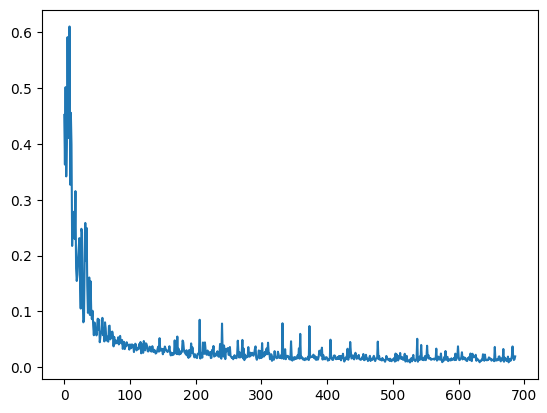

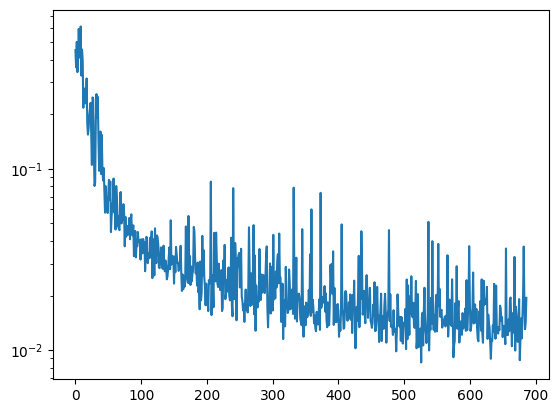

In [ ]:
import matplotlib.pyplot as plt
#Plotting the normal loss curve
plt.plot(train_loss)
plt.show()

#plotting the log-loss curve to see tendency more clearly 
plt.plot(train_loss)
plt.yscale("log")
plt.show()

In [14]:
#Shamelessly ai-gererated code to convert the gymnasium obs into something lerobot is able to process
import torch.nn.functional as F

def gym_to_lerobot_obs(env, gym_obs, task_prompt, device):
    # 1. env.render() returns a batched torch.Tensor of shape (B, H, W, 3) on GPU
    img = env.render()
    if not isinstance(img, torch.Tensor):
        img = torch.as_tensor(img)

    # Permute from (B, H, W, C) to (B, C, H, W) and normalize to [0, 1]
    img_tensor = img.permute(0, 3, 1, 2).float().to(device) / 255.0

    # Resize to match PolicyFeature shape (3, 128, 128) if needed
    if img_tensor.shape[-2:] != (128, 128):
        img_tensor = F.interpolate(img_tensor, size=(128, 128), mode="bilinear", align_corners=False)

    # 2. Extract proprioception or flat state depending on obs_mode
    if isinstance(gym_obs, dict):
        if "agent" in gym_obs and "qpos" in gym_obs["agent"]:
            state = gym_obs["agent"]["qpos"]
        else:
            raise KeyError(f"Unexpected dict structure. Available keys: {list(gym_obs.keys())}")
    else:
        state = gym_obs

    if not isinstance(state, torch.Tensor):
        state = torch.as_tensor(state)

    state_tensor = state.float().to(device)
    if state_tensor.ndim == 1:
        state_tensor = state_tensor.unsqueeze(0)

    #Slicing in case the dof is not 9. 
    #expected_state_dim = policy.config.input_features["observation.state"].shape[0]
    #state_tensor = state_tensor[..., :expected_state_dim]

    return {
        "observation.images.base_camera": img_tensor,
        "observation.state": state_tensor,
        "task": [task_prompt] * state_tensor.shape[0],
    }

In [32]:
#maniskill rendering. Need work to convert gymnasium observation to lerobot dict.  
import gymnasium as gym
import mani_skill.envs

env = gym.make(
    "PickCube-v1", # there are more tasks e.g. "PickCube-v1", "PegInsertionSide-v1", ...
    num_envs=1,
    obs_mode="state", # there is also "state_dict", "rgbd", ...
    control_mode="pd_ee_delta_pose", # there is also "pd_joint_delta_pos", ...
    render_mode = "rgb_array"
)

print("Observation space", env.observation_space)
print("Action space", env.action_space)

obs, _ = env.reset(seed=0) # reset with a seed for determinism
done = False
while not done:
    action = env.action_space.sample() # needs to be the policy inference action 
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    env.render()  # a display is required to render
env.close()

[2026-11-20 13:55:08.868] [SAPIEN] [warning] A PhysX CPU system is being created while PhysX GPU is enabled. You can safely ignore this message if it is intended. To use GPU PhysX, create a sapien.physx.PhysxGpuSystem explicitly and pass it to sapien.Scene constructor.


Observation space Box(-inf, inf, (1, 42), float32)
Action space Box(-1.0, 1.0, (7,), float32)


In [15]:
#Evaluation copied from the maniskill docs and changed to fit lerobot smolvla
import gymnasium as gym
import torch
from collections import defaultdict
from mani_skill.vector.wrappers.gymnasium import ManiSkillVectorEnv

env_id = "PickCube-v1"
num_eval_envs = 64
env_kwargs = dict(obs_mode="state_dict") # modify your env_kwargs here

models = {
    "control_policy": control_policy, 
    "trained_policy" : policy}

for name, policy in models.items():
    eval_envs = gym.make(
        env_id, 
        num_envs=num_eval_envs, 
        reconfiguration_freq=1, 
        **env_kwargs, 
        render_mode = "rgb_array", 
        # the default for maniskill is panda with 9 dof, so we need the env to match that.
        # "pd_ee_delta_pose" is a control mode with 9 dof, which is what we want
        control_mode = "pd_ee_delta_pose") 
    # add any other wrappers here
    eval_envs = ManiSkillVectorEnv(eval_envs, ignore_terminations=True, record_metrics=True)



    policy.reset()
    policy.eval()
    # evaluation loop, which will record metrics for complete episodes only
    obs, _ = eval_envs.reset(seed=0)
    eval_metrics = defaultdict(list)

    task = "Pick up the cube"

    done = None

    print(f"evaluation for model: {name} \n_________________________________________________")
    for _ in tqdm(range(200)):
        obs = gym_to_lerobot_obs(eval_envs, obs, task, device = device)

        with torch.inference_mode():
            obs = preprocess(obs)
            action = policy.select_action(obs)
            action = postprocess(action)

        if action.ndim == 1:
            action = action.unsqueeze(0)
        gym_action = action.cpu().numpy()
        obs, rew, terminated, truncated, info = eval_envs.step(gym_action)
        # note as there are no partial resets, truncated is True for all environments at the same time

        if truncated.any():
            for k, v in info["final_info"]["episode"].items():
                eval_metrics[k].append(v.float())

    
    for k in eval_metrics.keys():
        print(f"{k}_mean: {torch.mean(torch.stack(eval_metrics[k])).item()}")


    eval_envs.close()
        

/home/dl01e26/.conda/envs/vla/lib/python3.10/contextlib.py:135: UserWarning: CUDA reports that you have 2 available devices, and you have used fork_rng without explicitly specifying which devices are being used. For safety, we initialize *every* CUDA device by default, which can be quite slow if you have a lot of CUDAs. If you know that you are only making use of a few CUDA devices, set the environment variable CUDA_VISIBLE_DEVICES or the 'devices' keyword argument of fork_rng with the set of devices you are actually using. For example, if you are using CPU only, set device.upper()_VISIBLE_DEVICES= or devices=[]; if you are using device 0 only, set CUDA_VISIBLE_DEVICES=0 or devices=[0].  To initialize all devices and suppress this warning, set the 'devices' keyword argument to `range(torch.cuda.device_count())`.
  return next(self.gen)


evaluation for model: control_policy 
_________________________________________________


100%|██████████| 200/200 [00:26<00:00,  7.48it/s]


success_once_mean: 0.0
return_mean: 1.430823802947998
episode_len_mean: 50.0
reward_mean: 0.02861647680401802
success_at_end_mean: 0.0
evaluation for model: trained_policy 
_________________________________________________


100%|██████████| 200/200 [00:21<00:00,  9.38it/s]


success_once_mean: 0.00390625
return_mean: 3.55538272857666
episode_len_mean: 50.0
reward_mean: 0.0711076557636261
success_at_end_mean: 0.00390625


In [ ]:
print(policy.config.input_features["observation.state"])

PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(9,))


In [16]:
#rendering a video for evaluation of model
import mani_skill.envs
from mani_skill.utils.wrappers.record import RecordEpisode

video_env = gym.make(
    "PickCube-v1", 
    num_envs = 1, 
    obs_mode = "state_dict", 
    render_mode = "all", #we get all the camera and sensor feeds
    control_mode = "pd_ee_delta_pose" #again to have 9 dof
)

video_env = RecordEpisode(
    video_env,
    output_dir = "videos",
    save_video = True,
    save_trajectory = False, 
    video_fps = 30,
)

obs, _  = video_env.reset(seed = 0)

for i in range(200):
    obs = gym_to_lerobot_obs(video_env, obs, task, device = device)
    with torch.inference_mode():
        batch = preprocess(obs)
        action = policy.select_action(batch)
        action = postprocess(action)

    obs, _, terminated, truncated, info = video_env.step(action)

    if terminated or truncated:
        obs, _ = video_env.reset()

video_env.close()

[2026-11-23 13:38:21.536] [SAPIEN] [warning] A PhysX CPU system is being created while PhysX GPU is enabled. You can safely ignore this message if it is intended. To use GPU PhysX, create a sapien.physx.PhysxGpuSystem explicitly and pass it to sapien.Scene constructor.
